# Part 1: Perceptron → Multi-Layer Perceptron
**⏱ This section takes approximately 30 minutes.**

---

## Scenario: Late morning — From One Neuron to Many

This morning Sarah saw logistic regression score AUC ~0.76. That's a single perceptron in disguise. Today she sees what stacking multiple perceptrons does — and trains her first proper neural network with `sklearn.neural_network.MLPClassifier`.

**By the end of this notebook you will be able to:**
- Describe what a single perceptron computes
- Demonstrate WHY a single perceptron can't learn XOR
- See a multi-layer network solve XOR
- Train an MLP on Sarah's session data + compare to L03 baseline

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (11, 5)

np.random.seed(42)
print("✅ Libraries loaded — MLPClassifier ready")

✅ Libraries loaded — MLPClassifier ready


## Step 1 — The XOR problem (why one layer isn't enough)

**Where we are so far.** In the pre-class notebook we trained a **logistic regression** on the session data and got AUC ~0.76. Logistic regression is the simplest neural network there is: a **single perceptron** — one neuron that takes a weighted sum of the inputs, passes it through an activation, and outputs a probability. Because that sum is linear, a single perceptron can only carve the input space with a **straight line** (a flat plane in higher dimensions). That's its hard limit.

**What we're doing now.** Before we throw a bigger network at the real data, we want to *see* that limit clearly — and see what adding a hidden layer buys us. The cleanest demonstration is a tiny toy problem called **XOR**.

**What is XOR?** "Exclusive OR" is a logic rule: the output is `1` when the two inputs are *different*, and `0` when they're the *same*. Here's the truth table:

| x₁ | x₂ | y |
|---|---|---|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Plotted, the `y=1` points sit in **opposite corners** of a square. The question to keep in mind: **can a single STRAIGHT LINE separate the `y=1` points from the `y=0` points?** (Try drawing one — you can't. That impossibility is the whole point.)

We'll generate a slightly noisy version of these four corners so the classifiers have something realistic to train on.

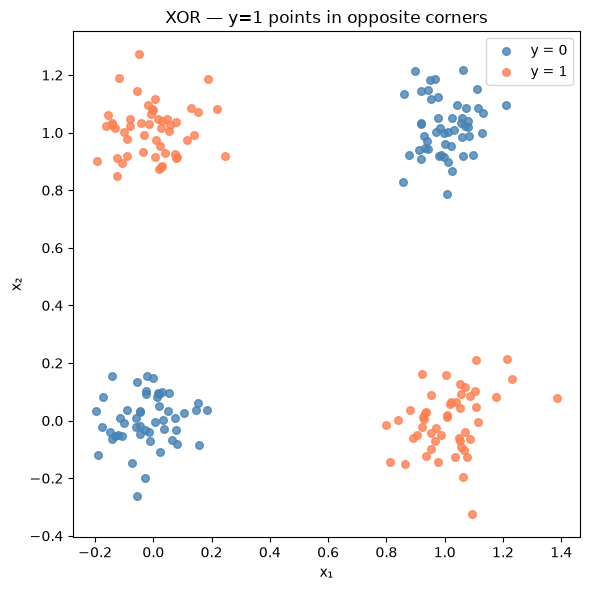

In [2]:
# XOR = the classic "no straight line can separate these" problem. The y=1 points sit in
# opposite corners. We make a noisy version (a fuzzy blob at each corner) so classifiers can train on it.
n_per_corner = 50   # 50 points clustered around each of the 4 corners
xor_data = np.vstack([
    # np.random.normal(centre, spread, n) = a fuzzy cloud of points around a corner
    np.column_stack((np.random.normal(0, 0.1, n_per_corner), np.random.normal(0, 0.1, n_per_corner))),  # (0,0) → 0
    np.column_stack((np.random.normal(0, 0.1, n_per_corner), np.random.normal(1, 0.1, n_per_corner))),  # (0,1) → 1
    np.column_stack((np.random.normal(1, 0.1, n_per_corner), np.random.normal(0, 0.1, n_per_corner))),  # (1,0) → 1
    np.column_stack((np.random.normal(1, 0.1, n_per_corner), np.random.normal(1, 0.1, n_per_corner))),  # (1,1) → 0
])
# the matching labels, in the same corner order as above
xor_labels = np.concatenate([np.zeros(n_per_corner), np.ones(n_per_corner),
                              np.ones(n_per_corner), np.zeros(n_per_corner)])

# Plot the two classes in different colours. Notice y=1 (coral) sits in diagonally opposite corners.
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(xor_data[xor_labels==0, 0], xor_data[xor_labels==0, 1],
           color="steelblue", label="y = 0", s=30, alpha=0.8)
ax.scatter(xor_data[xor_labels==1, 0], xor_data[xor_labels==1, 1],
           color="coral", label="y = 1", s=30, alpha=0.8)
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.set_title("XOR — y=1 points in opposite corners")
ax.legend()
plt.tight_layout(); plt.show()

## Step 2 — A single perceptron can't solve XOR (but a multi-layer one can)

Now we train two models on the XOR data and compare their **decision boundaries** (the line or curve a model draws to separate its "yes" region from its "no" region).

**Model A — a single perceptron.** Logistic regression *is* a single perceptron: it computes one weighted sum of the inputs and squashes it with a sigmoid. Geometrically it can only place a **straight line**. Since no straight line separates XOR's opposite corners, it's stuck near 50% accuracy — coin-flip territory. **This is exactly the shortcoming we saw with linear models on non-linear relationships.**

**Model B — a multi-layer perceptron (MLP).** An MLP fixes this by stacking neurons into **layers**:

- The **input layer** is just the raw features (`x₁`, `x₂`).
- A **hidden layer** (here, 8 neurons) sits in the middle. Each neuron computes its own weighted sum of the inputs and then applies a **non-linear activation** (ReLU here — it zeros out negatives). You can think of each hidden neuron as learning its own straight-line "question" about the data.
- The **output layer** combines those hidden answers into the final prediction.

**Why does stacking help?** The non-linear activation between layers is the key. The output layer combines several straight-line pieces from the hidden layer into a **bent, non-linear boundary** that can wrap around XOR's corners. Crucially, the non-linearity is what does it — *stacking linear layers with no activation in between just collapses back into one big linear layer (still a straight line).* The activation is what unlocks the extra expressive power.

Watch how the single perceptron's boundary stays a flat line while the MLP's boundary curves to capture the pattern.

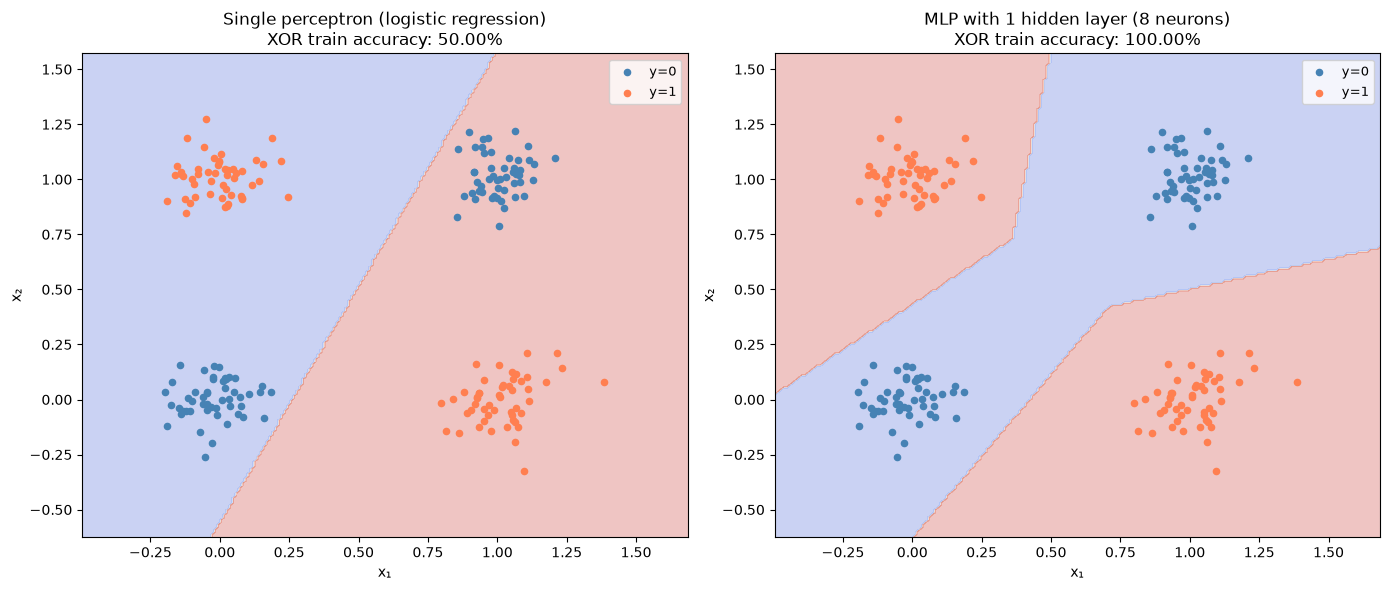

Single perceptron accuracy:  50.00%  (≈ 50% — can't beat chance on XOR)
MLP with 1 hidden layer:     100.00%  (near 100% — learns the pattern)


In [3]:
# Helper: shade the whole plane by what the model would predict at each point, then scatter the data on top.
# The shaded regions reveal the model's "decision boundary" — the line/curve separating its yes from its no.
def plot_decision_boundary(model, X, y, ax, title):
    # build a fine grid of points covering the data range
    x_min, x_max = X[:, 0].min() - 0.3, X[:, 0].max() + 0.3
    y_min, y_max = X[:, 1].min() - 0.3, X[:, 1].max() + 0.3
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)   # predict at every grid point
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")                   # shade by prediction
    ax.scatter(X[y==0, 0], X[y==0, 1], color="steelblue", label="y=0", s=20)
    ax.scatter(X[y==1, 0], X[y==1, 1], color="coral", label="y=1", s=20)
    ax.set_title(title)
    ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.legend(fontsize=9)


# Model A: a SINGLE perceptron. Logistic regression is exactly that — it can only draw a STRAIGHT line.
single_perceptron = LogisticRegression()
single_perceptron.fit(xor_data, xor_labels)
acc_single = accuracy_score(xor_labels, single_perceptron.predict(xor_data))

# Model B: a multi-layer perceptron — one hidden layer of 8 neurons + ReLU lets it bend the boundary.
mlp_xor = MLPClassifier(hidden_layer_sizes=(8,), activation="relu",
                        max_iter=3000, random_state=42)
mlp_xor.fit(xor_data, xor_labels)
acc_mlp = accuracy_score(xor_labels, mlp_xor.predict(xor_data))

# Plot both side by side so the difference in boundary shape is obvious.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_decision_boundary(single_perceptron, xor_data, xor_labels, axes[0],
                       f"Single perceptron (logistic regression)\nXOR train accuracy: {acc_single:.2%}")
plot_decision_boundary(mlp_xor, xor_data, xor_labels, axes[1],
                       f"MLP with 1 hidden layer (8 neurons)\nXOR train accuracy: {acc_mlp:.2%}")
plt.tight_layout(); plt.show()

print(f"Single perceptron accuracy:  {acc_single:.2%}  (≈ 50% — can't beat chance on XOR)")
print(f"MLP with 1 hidden layer:     {acc_mlp:.2%}  (near 100% — learns the pattern)")

### 💡 What you should notice

- **Single perceptron** (left): the decision boundary is a STRAIGHT LINE. There's no straight line that separates the corners correctly. Accuracy is around 50% — chance-level.
- **MLP** (right): the decision boundary CURVES around the corners. The hidden layer + non-linear activation lets the network represent non-linear functions.

This is the proof that multi-layer + non-linear activation = qualitatively different model class. Stacking linear layers without non-linearity in between is still linear; the non-linearity is what unlocks expressive power.

## ⏸️ Pause and Predict

Sarah's session data has 9 features. Will an MLP beat the L03 logistic regression baseline (AUC 0.76)?

Predict:
- How much better do you expect MLP to be? (+0.01? +0.05? +0.10?)
- Will deeper (3+ layers) be much better than 1 hidden layer?

> *Common prediction:* "The MLP is non-linear, so if the data has feature interactions it should beat LR by a few points (+0.03 to +0.07 AUC)." Hold that thought — the next cell tests it. A useful prior to also keep in mind: on small, well-engineered tabular data, extra capacity often has little signal to find, and depth past 2-3 hidden layers rarely helps — it just adds parameters.

## Step 3 — Train an MLPClassifier on the session data

Now we leave the XOR toy behind and train a real MLP (two hidden layers, **32 → 16** neurons) on Sarah's 9-feature session data, then print three numbers. Here's how to read them:

- **Accuracy** — the fraction of test sessions where the yes/no prediction was correct. `0.699` ≈ right about 70% of the time.
- **AUC** (Area Under the ROC Curve) — a ranking score. Pick one session that completed and one that didn't, at random: AUC is the probability the model gives the completed one a higher score. `1.0` = perfect, `0.5` = no better than a coin flip. We lean on AUC because, unlike accuracy, it doesn't depend on where you set the 0.5 cutoff and it handles class imbalance gracefully.
- **# parameters** — the count of weights the network learned. It comes from the connections *between* layers: every neuron in one layer connects to every neuron in the next, and each connection is one weight. With 9 inputs → 32 → 16 → 1 output, the weight counts are `9×32 + 32×16 + 16×1 = 288 + 512 + 16 = 816`. (That's what the `sum(c.size for c in ...coefs_)` line adds up; `coefs_` holds one weight matrix per layer gap. Biases would add a few more, but `coefs_` counts just the connection weights.) Compare that to logistic regression's 9 weights (one per feature) — the MLP has far more knobs to tune.

In [4]:
# Load the session data + same preprocessing pipeline as L03
df = pd.read_csv("data/northstar_sessions.csv")
y = df["completed"]                                  # the label: completed checkout? (1/0)
X = df.drop(columns=["session_id", "completed"])     # the 9 behaviour features

# Same 80/20 split as the L03 baseline, so the comparison is fair.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42,
)

# Fill missing values with the median, then rescale to mean 0 / std 1 (neural nets need scaled inputs).
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("scl", StandardScaler())]), X.columns.tolist()),
])

# The model: an MLP with two hidden layers. The pipeline runs preprocessing then the MLP.
mlp_pipe = Pipeline([
    ("prep",  preprocessor),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),    # 2 hidden layers: first 32 neurons, then 16
        activation="relu",              # non-linearity between layers (what makes it more than linear)
        solver="adam",                  # the optimiser that adjusts the weights
        max_iter=500,                   # max passes over the data
        early_stopping=True,            # stop early if a held-out slice stops improving
        validation_fraction=0.15,       # use 15% of train as that held-out slice
        random_state=42,
    )),
])

mlp_pipe.fit(X_train, y_train)                       # preprocess + train in one call

y_pred_mlp = mlp_pipe.predict(X_test)                # yes/no predictions
y_proba_mlp = mlp_pipe.predict_proba(X_test)[:, 1]   # probability of "completed", for AUC

print(f"=== sklearn MLPClassifier (32 → 16 hidden) ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_mlp):.3f}")
print(f"AUC:       {roc_auc_score(y_test, y_proba_mlp):.3f}")
# coefs_ holds the weight matrices between layers; summing their sizes counts the learned weights
print(f"# parameters: {sum(c.size for c in mlp_pipe.named_steps['model'].coefs_):,}")

=== sklearn MLPClassifier (32 → 16 hidden) ===
Accuracy:  0.699
AUC:       0.757
# parameters: 816


In [5]:
# Train the L03 logistic-regression baseline on the SAME split, so we can compare like-for-like.
lr_pipe = Pipeline([
    ("prep",  preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
lr_pipe.fit(X_train, y_train)
y_pred_lr = lr_pipe.predict(X_test)
y_proba_lr = lr_pipe.predict_proba(X_test)[:, 1]

# Print both models' scores together. On this tabular data they come out nearly tied.
print("Side by side:")
print(f"  Logistic Regression: Accuracy {accuracy_score(y_test, y_pred_lr):.3f}, AUC {roc_auc_score(y_test, y_proba_lr):.3f}")
print(f"  MLP (32→16):        Accuracy {accuracy_score(y_test, y_pred_mlp):.3f}, AUC {roc_auc_score(y_test, y_proba_mlp):.3f}")

Side by side:
  Logistic Regression: Accuracy 0.703, AUC 0.761
  MLP (32→16):        Accuracy 0.699, AUC 0.757


### 📈 Picture the comparison

Two numbers that differ in the third decimal place are hard to judge. Let's **draw** both models:
- **Left — ROC curves** (the same chart as in the pre-class notebook). The bigger the area under a curve, the better that model ranks sessions.
- **Right — the two models' scores for every test session.** Each dot is one session: its position across is the logistic regression's score, and its position up is the MLP's score.

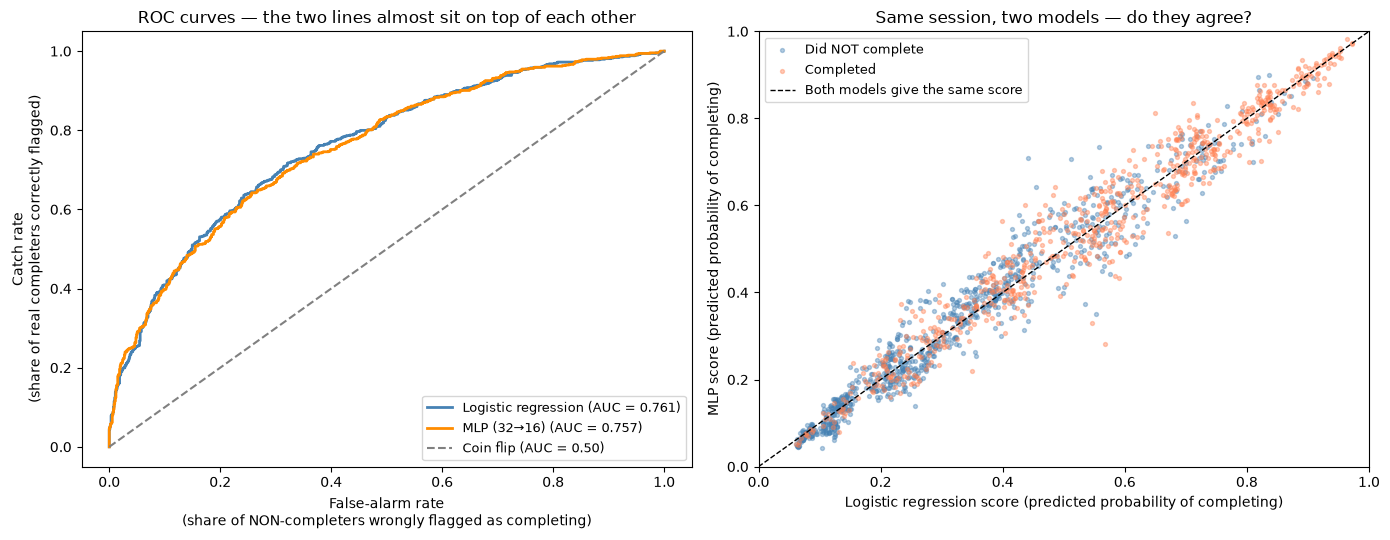

Correlation between LR and MLP scores:     0.98
Sessions where both make the same yes/no:  94%


In [6]:
from sklearn.metrics import roc_curve

auc_lr  = roc_auc_score(y_test, y_proba_lr)
auc_mlp = roc_auc_score(y_test, y_proba_mlp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Left: both ROC curves on one chart ---
ax = axes[0]
for proba, name, color, auc in [(y_proba_lr,  "Logistic regression", "steelblue", auc_lr),
                                (y_proba_mlp, "MLP (32→16)",         "darkorange", auc_mlp)]:
    fpr, tpr, _ = roc_curve(y_test, proba)       # every cut-off → (false-alarm rate, catch rate)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="Coin flip (AUC = 0.50)")
ax.set_xlabel("False-alarm rate\n(share of NON-completers wrongly flagged as completing)")
ax.set_ylabel("Catch rate\n(share of real completers correctly flagged)")
ax.set_title("ROC curves — the two lines almost sit on top of each other")
ax.legend(loc="lower right", fontsize=9)

# --- Right: does the MLP score sessions differently from LR? ---
ax = axes[1]
y_arr = y_test.values
ax.scatter(y_proba_lr[y_arr == 0], y_proba_mlp[y_arr == 0], s=8, alpha=0.4, color="steelblue", label="Did NOT complete")
ax.scatter(y_proba_lr[y_arr == 1], y_proba_mlp[y_arr == 1], s=8, alpha=0.4, color="coral",     label="Completed")
ax.plot([0, 1], [0, 1], "--", color="black", linewidth=1, label="Both models give the same score")
ax.set_xlabel("Logistic regression score (predicted probability of completing)")
ax.set_ylabel("MLP score (predicted probability of completing)")
ax.set_title("Same session, two models — do they agree?")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper left", fontsize=9)

plt.tight_layout(); plt.show()

# How closely do the two models agree? 1.0 = identical scores, 0 = unrelated.
corr = np.corrcoef(y_proba_lr, y_proba_mlp)[0, 1]
same_call = ((y_proba_lr >= 0.5) == (y_proba_mlp >= 0.5)).mean()
print(f"Correlation between LR and MLP scores:     {corr:.2f}")
print(f"Sessions where both make the same yes/no:  {same_call:.0%}")


### 💡 How to read the chart

- **Left:** the blue and orange curves are almost on top of each other, so the areas under them (the AUCs) are almost equal. Where one curve pokes slightly above the other, that model is a touch better *at that cut-off* — but the gaps are tiny and change direction along the curve.
- **Right:** if the MLP had found patterns that logistic regression missed, the dots would scatter widely away from the dashed line. Instead they hug it: **the two models score almost every session the same way**, and make the same yes/no call on most of them (see the printed numbers).
- **Why?** The MLP *can* learn curved, non-linear patterns (we just saw it solve XOR). Here it barely uses that power, because the signal in these 9 features is mostly straight-line. When the simpler model already captures the pattern, extra flexibility has nothing extra to find.

### 💡 What you should notice

- **MLP and LR are essentially TIED on this dataset (AUC ~0.76 each)**.
- This is **realistic for tabular data with modest size and feature counts**. The XOR demo shows what neural networks CAN do that LR can't — but for many real tabular problems, gradient boosting (L04) is the practical winner.
- **The MLP has many more parameters** (816 weights vs LR's 9). The capacity is there — but with 8,000 rows and only 9 features, there's not enough signal for the extra capacity to find.

**The honest finding:** for THIS task, sticking with logistic regression or gradient boosting is the right deployment choice. The MLP isn't the right tool for every tabular problem.

**Why we still learn this:** the MLP is the foundation for L08 (images), L09 (text), and L10 (transformers). On those data types, neural networks aren't just competitive — they're the ONLY practical choice.

## Step 4 — Vary the architecture: how many layers? how many neurons?

A common question: how do I choose the architecture? For tabular data, "deeper" isn't always "better." Try a few configurations.

In [7]:
# Does a bigger/deeper network help? Try five architectures from tiny to large.
# Each tuple = neurons per hidden layer, e.g. (64, 32, 16) means three layers of those sizes.
configs = [
    ("1 layer × 8 neurons",     (8,)),
    ("1 layer × 32 neurons",    (32,)),
    ("2 layers, 32 → 16",        (32, 16)),
    ("3 layers, 64 → 32 → 16",   (64, 32, 16)),
    ("4 layers, 128 → 64 → 32 → 16", (128, 64, 32, 16)),
]

records = []
for name, hidden in configs:                         # train one model per architecture
    pipe = Pipeline([
        ("prep",  preprocessor),
        ("model", MLPClassifier(
            hidden_layer_sizes=hidden, activation="relu",
            max_iter=500, early_stopping=True, random_state=42,
        )),
    ])
    pipe.fit(X_train, y_train)
    auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])      # test-set ranking quality
    train_auc = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])   # same score on the data it learned from
    n_params = sum(c.size for c in pipe.named_steps["model"].coefs_)   # how many weights this size needs
    records.append((name, n_params, train_auc, auc))

# Table of architecture vs parameter count vs score — note the AUC barely moves as size grows.
result_df = pd.DataFrame(records, columns=["Configuration", "# params", "Train AUC", "Test AUC"])
print(result_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

               Configuration  # params  Train AUC  Test AUC
         1 layer × 8 neurons        80      0.770     0.751
        1 layer × 32 neurons       320      0.785     0.758
           2 layers, 32 → 16       816      0.784     0.760
      3 layers, 64 → 32 → 16      3152      0.787     0.758
4 layers, 128 → 64 → 32 → 16     11920      0.785     0.760


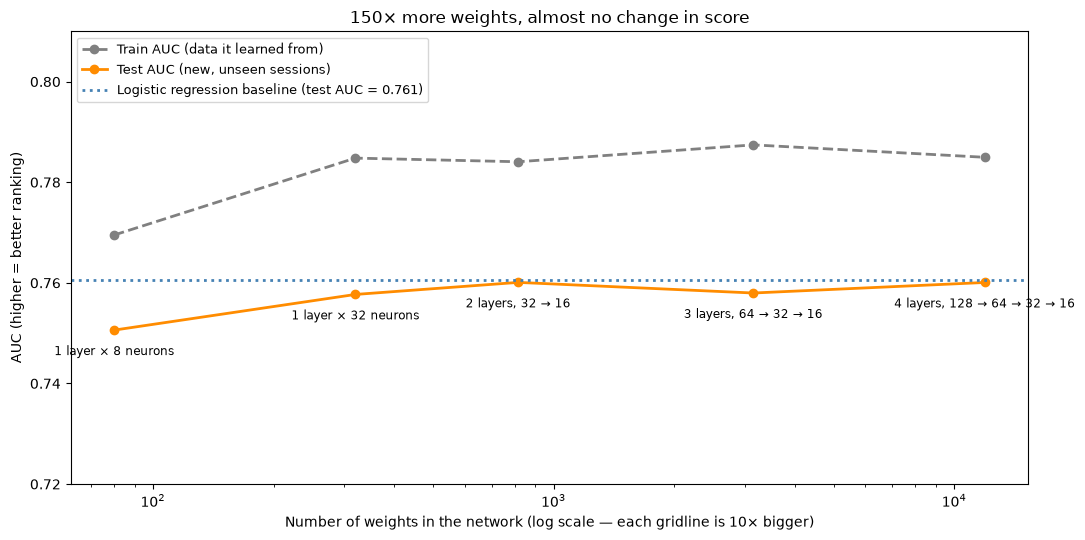

In [8]:
# Plot score vs model size. Size grows ~150× from left to right, so use a log scale on the x-axis.
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(result_df["# params"], result_df["Train AUC"], "o--", color="gray",       linewidth=2, label="Train AUC (data it learned from)")
ax.plot(result_df["# params"], result_df["Test AUC"],  "o-",  color="darkorange", linewidth=2, label="Test AUC (new, unseen sessions)")
ax.axhline(roc_auc_score(y_test, y_proba_lr), color="steelblue", linestyle=":", linewidth=2,
           label=f"Logistic regression baseline (test AUC = {roc_auc_score(y_test, y_proba_lr):.3f})")

# Label each point with its architecture
for _, row in result_df.iterrows():
    ax.annotate(row["Configuration"], (row["# params"], row["Test AUC"]),
                textcoords="offset points", xytext=(0, -18), ha="center", fontsize=8.5)

ax.set_xscale("log")
ax.set_xlabel("Number of weights in the network (log scale — each gridline is 10× bigger)")
ax.set_ylabel("AUC (higher = better ranking)")
ax.set_title("150× more weights, almost no change in score")
ax.set_ylim(0.72, 0.81)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()


### 💡 What you should notice

- **The AUC barely moves across all five architectures** (≈0.75–0.76) — from a single 8-neuron layer up to four layers with ~12k weights. Differences this small are noise.
- **More parameters doesn't mean better.** On the chart, the orange test line is flat: going from 80 to ~12,000 weights never lifts the MLP clearly above the blue logistic-regression line.
- **Read the gap between the grey and orange lines.** Train AUC is always a bit higher than test AUC (~0.02–0.03) — every model does slightly better on data it has already seen. If a bigger network were *memorising* the training data, the grey line would climb and the gap would widen. Here it doesn't, because `early_stopping=True` halts training once a held-out slice stops improving. Without that guard, bigger networks are generally more prone to overfitting — more weights give them more room to memorise.
- **For TABULAR data, start modest (1-3 hidden layers, 16-128 neurons each)** — bigger rarely helps. Deeper networks shine on images and text where the data has rich hierarchical structure.

## ✅ Section Summary

| Step | Output |
|---|---|
| **XOR demo** | Single perceptron fails; MLP succeeds — proof that depth + non-linearity matters |
| **MLP on session data** | AUC ~0.76 — tied with LR on THIS tabular problem |
| **Architecture sweep** | AUC flat (~0.76) from 1 to 4 layers — a modest network is enough for this tabular data |

**Key insights:**
- **A perceptron is one neuron.** A linear function + activation.
- **An MLP is many perceptrons in stacked layers.** Non-linear activation between layers is what makes it expressive.
- **Sklearn MLPClassifier is the quickest way to train an MLP.** But it abstracts away the training loop — for that, we'll use PyTorch.

---
**Up next → Part 2:** gradient descent intuition + PyTorch basics. The mountain analogy, then your first PyTorch model.
Open `03_gradient_descent.ipynb`

---

## 🟡 Extension — self-study after class

*Skipping this section will not affect your understanding of later lessons. Come back to it when you have time and want to go deeper.*

## Extension 1 — Visualise an MLP's decision boundary on a 2D dataset

We can't visualise a 9-feature decision boundary directly. But we CAN visualise the model on the XOR data we used at the start. Let's animate decision-boundary evolution with increasing training iterations.

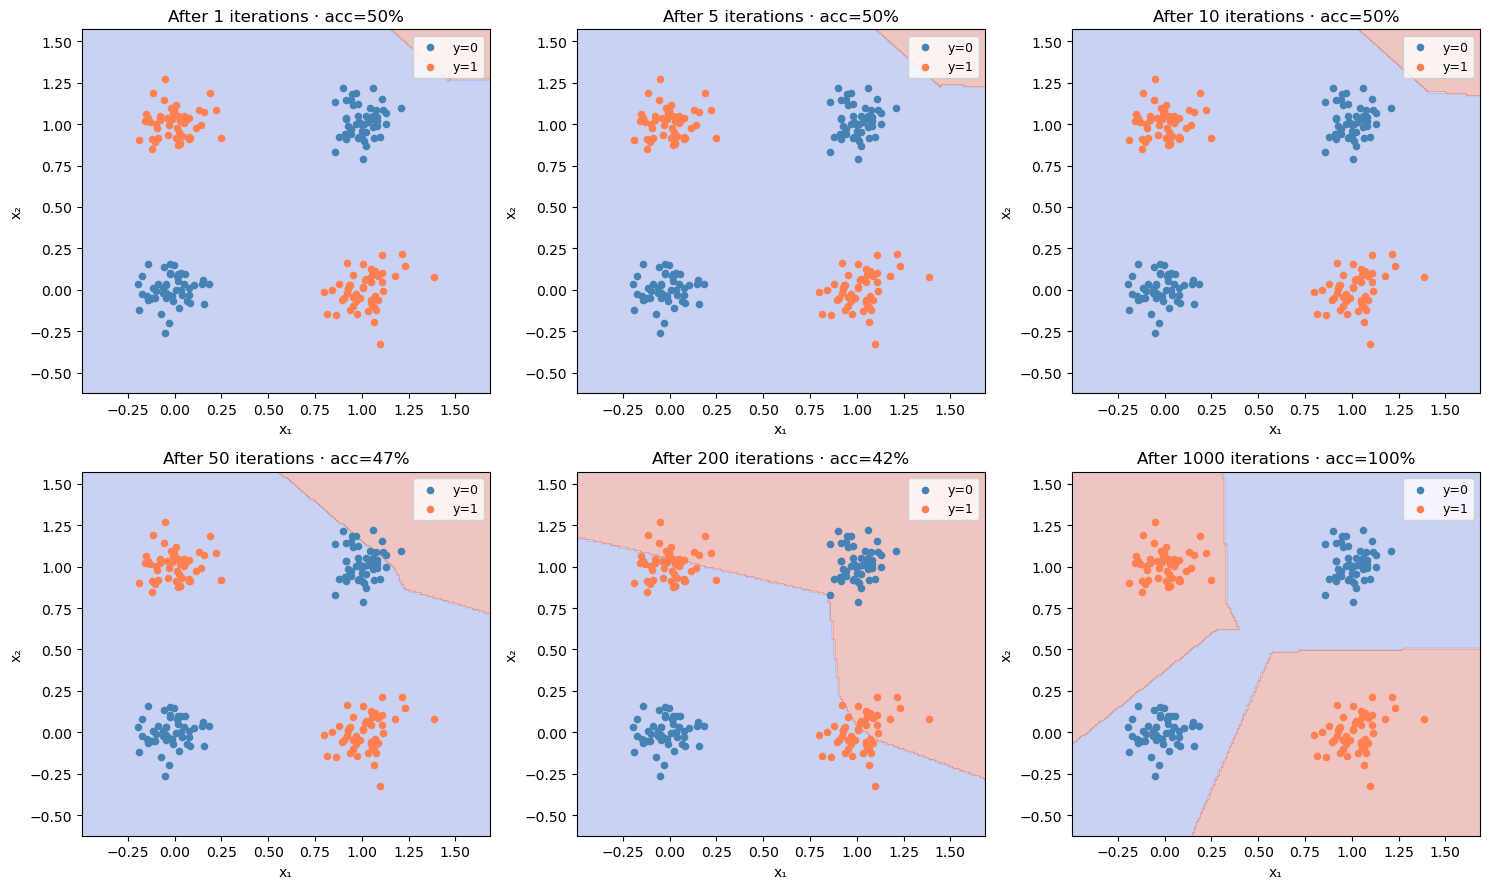

As training progresses, the decision boundary EVOLVES from random → curved.
This is gradient descent doing its work, one update at a time.


In [9]:
from sklearn.neural_network import MLPClassifier

# Watch the SAME MLP learn over time: train it for more and more iterations and snapshot the boundary.
# max_iter caps how many training passes it gets — so each panel is "the model after N passes".
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, n_iter in zip(axes.flat, [1, 5, 10, 50, 200, 1000]):
    m = MLPClassifier(hidden_layer_sizes=(8,), activation="relu",
                      max_iter=n_iter, warm_start=False, random_state=42)
    m.fit(xor_data, xor_labels)                              # train from scratch for n_iter passes
    acc = accuracy_score(xor_labels, m.predict(xor_data))
    plot_decision_boundary(m, xor_data, xor_labels, ax,      # reuse the helper from Step 2
                            f"After {n_iter} iterations · acc={acc:.0%}")
plt.tight_layout(); plt.show()
print("As training progresses, the decision boundary EVOLVES from random → curved.")
print("This is gradient descent doing its work, one update at a time.")

## Extension 2 — Sigmoid vs ReLU vs Tanh

Different activation functions. Let's plot them side by side.

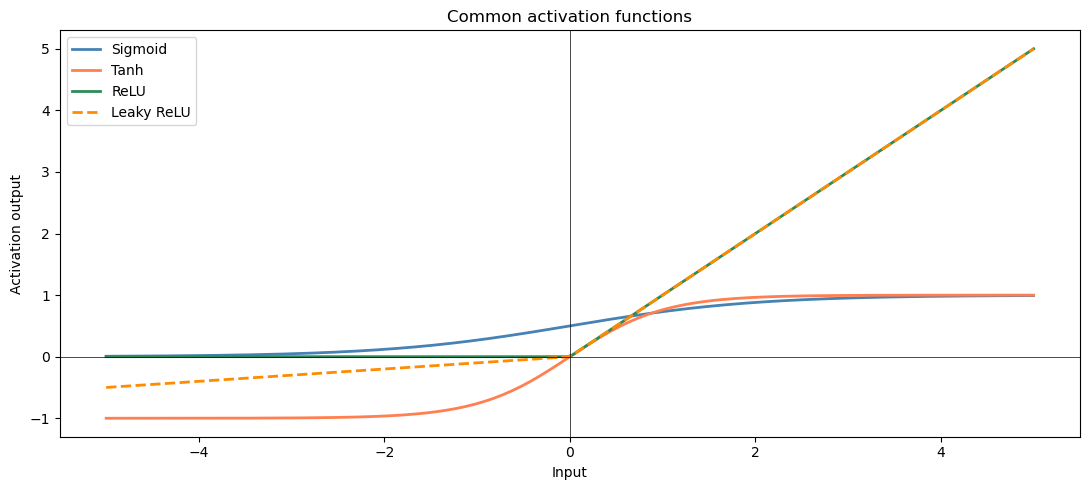

Sigmoid (older networks, output layer for binary classification):
  - Saturates → gradients vanish for large |x|

Tanh:
  - Same shape as sigmoid but centred on 0; rarely used now

ReLU (default for hidden layers):
  - Fast, simple, doesn't saturate on the positive side
  - 'Dead' neurons: if input < 0 always, the neuron never fires

Leaky ReLU:
  - Variant of ReLU with small negative slope; fixes dead neurons


In [10]:
# An "activation function" is the non-linear squashing each neuron applies to its weighted sum.
# It's what lets a network bend its decision boundary instead of staying linear. Let's plot the common ones.
x = np.linspace(-5, 5, 200)              # a range of input values to feed each function
sigmoid = 1 / (1 + np.exp(-x))           # squashes any input into (0, 1)
tanh = np.tanh(x)                        # squashes into (-1, 1), centred on 0
relu = np.maximum(0, x)                  # keep positives, zero out negatives — the modern default
leaky_relu = np.where(x > 0, x, 0.1 * x) # like ReLU but lets a trickle through for negatives

# Plot all four on the same axes to compare their shapes.
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, sigmoid, label="Sigmoid", linewidth=2, color="steelblue")
ax.plot(x, tanh, label="Tanh", linewidth=2, color="coral")
ax.plot(x, relu, label="ReLU", linewidth=2, color="seagreen")
ax.plot(x, leaky_relu, label="Leaky ReLU", linewidth=2, linestyle="--", color="darkorange")
ax.axhline(0, color="black", linewidth=0.5)   # reference lines through the origin
ax.axvline(0, color="black", linewidth=0.5)
ax.set_xlabel("Input"); ax.set_ylabel("Activation output")
ax.set_title("Common activation functions")
ax.legend()
plt.tight_layout(); plt.show()

print("Sigmoid (older networks, output layer for binary classification):")
print("  - Saturates → gradients vanish for large |x|")
print()
print("Tanh:")
print("  - Same shape as sigmoid but centred on 0; rarely used now")
print()
print("ReLU (default for hidden layers):")
print("  - Fast, simple, doesn't saturate on the positive side")
print("  - 'Dead' neurons: if input < 0 always, the neuron never fires")
print()
print("Leaky ReLU:")
print("  - Variant of ReLU with small negative slope; fixes dead neurons")